MCS 320 Quiz 11 Friday 20 November 2026

# Question 1

Use SymPy to solve the recurrence relation
$$
   T(n) = T(n-1) + T(n-2) + n,
$$
with initial conditions $T(0) = 0$, $T(1) = 1$.

Turn the solution into a SageMath function
which returns the value of the solution
for any value of the input argument $n$.

## answer to question 1

In [1]:
from sympy import Function, rsolve
from sympy.abc import n

In [2]:
T = Function('T')
equ = T(n+2) - T(n+1) - T(n) - n
show(equ)

-n - T(n) - T(n + 1) + T(n + 2)

In [3]:
sol = rsolve(equ,T(n), {T(0): 0, T(1): 1})
sol

-n + (1/2 - sqrt(5)/2)*(1/2 - sqrt(5)/2)**n + (1/2 + sqrt(5)/2)*(1/2 + sqrt(5)/2)**n - 1

In [4]:
fsol(N) = SR(sol)(n=N)
fsol

N |--> 1/2*(1/2*sqrt(5) + 1/2)^N*(sqrt(5) + 1) - 1/2*(-1/2*sqrt(5) + 1/2)^N*(sqrt(5) - 1) - N - 1

In [5]:
fsol(3).full_simplify()

3

# Question 2

Use SciPy to solve the second order initial value problem
$$
        \frac{d^2}{d~\!t^2} y(t) + 2 \frac{d}{d~\!t} y(t) + 5 y(t)
        = 50 \cos(t), \quad y(0) = 0, \quad y'(0) = 0.
$$
Make the phase portrait of the solution for $t \in [0,10]$.

## answer to question 2

In [6]:
reset()

In [7]:
t, y, dy = var('t, y, dy')
oderhs = [dy, 50*cos(t) - 2*dy - 5*y]
oderhs

[dy, -2*dy - 5*y + 50*cos(t)]

In [8]:
def rhs(y, t):
    return [y[1], 50*cos(t) - 2*y[1] - 5*y[0]]

In [9]:
rhs([y, dy], t)

[dy, -2*dy - 5*y + 50*cos(t)]

In [10]:
from scipy.integrate import odeint
from numpy import linspace
npts = 1000 # number of points
tspan = linspace(0, 10, npts)
sol = odeint(rhs, [0, 0], tspan)
sol

array([[ 0.00000000e+00,  0.00000000e+00],
       [ 2.48825768e-03,  4.95474073e-01],
       [ 9.88565354e-03,  9.80831881e-01],
       ...,
       [-1.11340317e+01,  1.02321811e+00],
       [-1.11232316e+01,  1.13461642e+00],
       [-1.11113170e+01,  1.24590053e+00]])

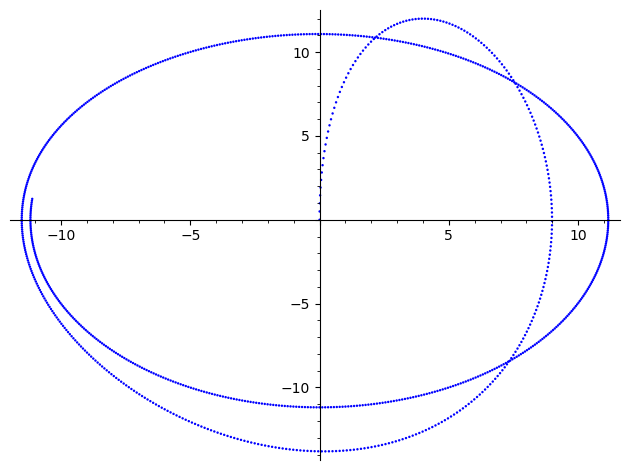

In [11]:
coords = [(sol[k][0], sol[k][1]) for k in range(npts)]
list_plot(coords, size=3)